In [35]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os


In [36]:

# --- Configuration ---
# Set Plot Style
sns.set_theme(style="whitegrid")

# File Paths
VISUALS_DATA_PATH = os.path.join('data_csv', 'visual_data.csv')
VAR_DATA_PATH = os.path.join('data_csv', 'var_data.csv')

# City Mapping
CITY_MAP = {
    'SF': 'San Francisco',
    'CE': 'Cleveland',
    'CR': 'Charlotte',
    'LV': 'Las Vegas',
    'NY': 'New York'
}


In [37]:

# --- Helper Functions ---
def load_data(path):
    """Loads CSV data with date parsing."""
    return pd.read_csv(path, index_col=0, parse_dates=True)

def plot_series(data, x=None, y=None, title=None, ylabel=None, xlabel='Year', xlim_right=None, figsize=(12, 6), palette=None, linewidth=2.5):
    """Generic plotting function for time series."""
    plt.figure(figsize=figsize)
    sns.lineplot(data=data, x=x, y=y, palette=palette, linewidth=linewidth)
    if title: plt.title(title)
    if ylabel: plt.ylabel(ylabel)
    if xlabel: plt.xlabel(xlabel)
    if xlim_right: plt.xlim(right=pd.Timestamp(xlim_right))
    plt.show()


In [38]:

# Load Data
df_visuals = load_data(VISUALS_DATA_PATH)
df_var = load_data(VAR_DATA_PATH)

print("Data Loaded Successfully.")
print("Visuals Data Range:", df_visuals.index.min(), "to", df_visuals.index.max())
print("VAR Data Range:", df_var.index.min(), "to", df_var.index.max())

Data Loaded Successfully.
Visuals Data Range: 1959-01-01 00:00:00 to 2025-08-01 00:00:00
VAR Data Range: 1987-01-01 00:00:00 to 2007-07-01 00:00:00


## 1. National Population and Permits
Comparing National Population (Left Axis) and Building Permits (Right Axis).

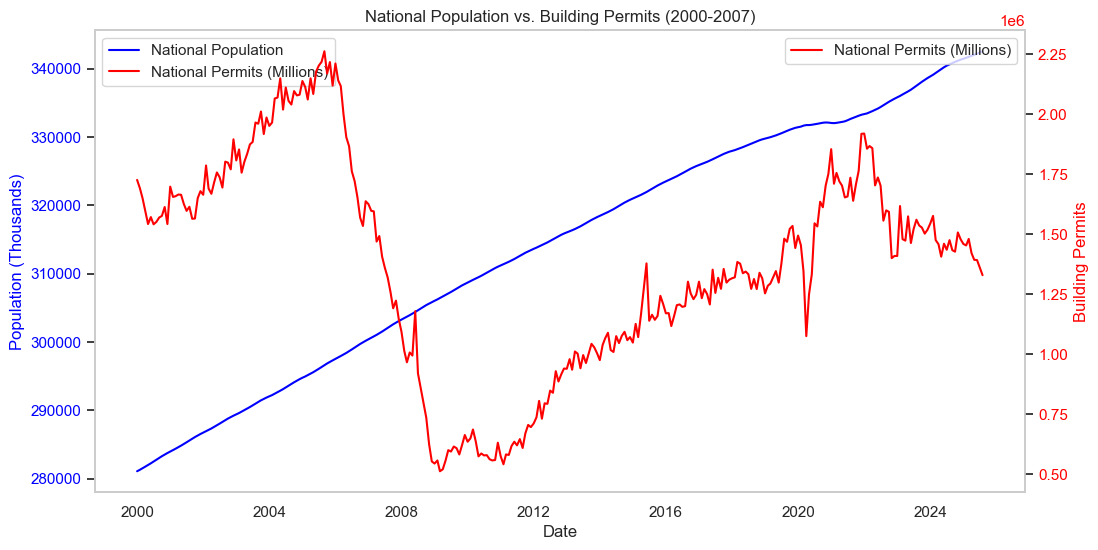

In [39]:
# Dual Axis Plot: Population vs Permits
fig, ax1 = plt.subplots(figsize=(12, 6))

# Left Axis: Population
sns.lineplot(data=df_visuals, x=df_visuals.index, y='National_population', ax=ax1, color='blue', label='National Population')
ax1.set_ylabel('Population (Thousands)', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_xlabel('Date')
ax1.grid(False)

# Right Axis: Permits
ax2 = ax1.twinx()
sns.lineplot(data=df_visuals, x=df_visuals.index, y='National_permits', ax=ax2, color='red', label='National Permits (Millions)')
ax2.set_ylabel('Building Permits', color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.grid(False)

plt.title('National Population vs. Building Permits (2000-2007)')

# Combine Legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.show()

## 2. Metro Level Permits
Trends in building permits for all metropolitan areas.

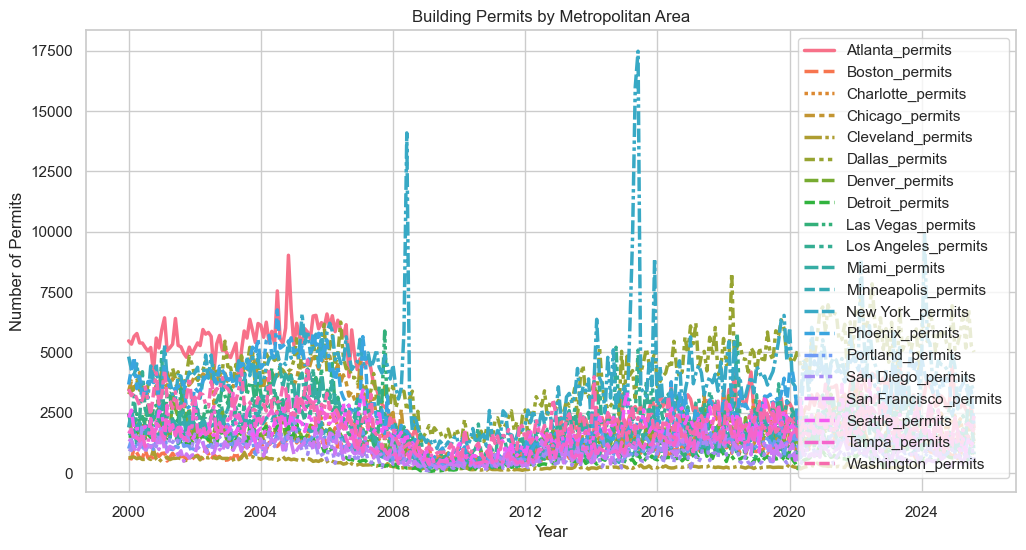

In [40]:
# Metro Permits
metro_permits_cols = [col for col in df_visuals.columns if 'permits' in col and 'National' not in col]
plot_series(df_visuals[metro_permits_cols], title='Building Permits by Metropolitan Area', ylabel='Number of Permits')

## 4. Permits per Capita
Calculating and visualizing Building Permits divided by Population for both National and Metro levels.
This metric helps normalize the permit data relative to the size of the population.

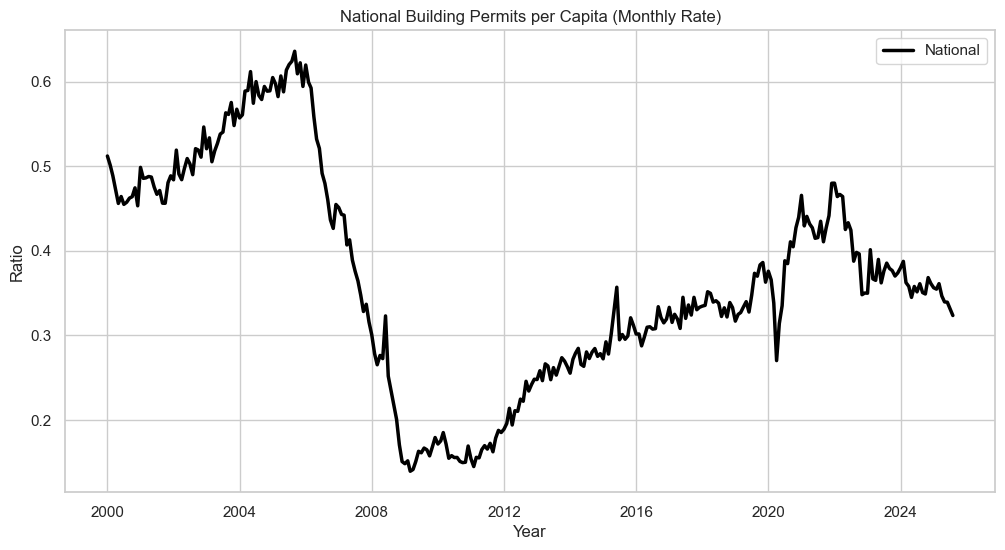

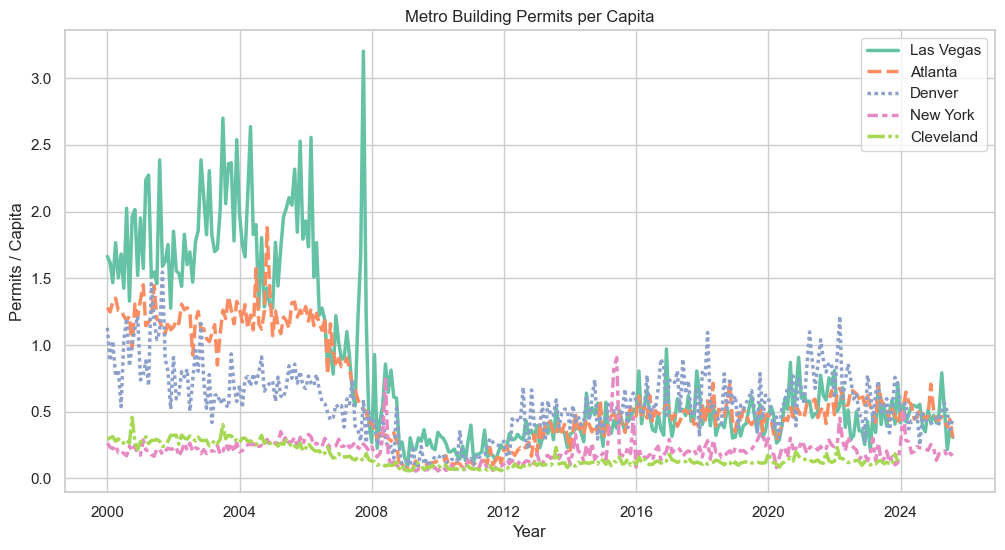

In [41]:
# Calculate Permits per Capita
df_per_capita = pd.DataFrame(index=df_visuals.index)

# National (Adjusted for monthly rate)
if 'National_permits' in df_visuals.columns and 'National_population' in df_visuals.columns:
    df_per_capita['National'] = (df_visuals['National_permits'] / df_visuals['National_population']) / 12

# Metros
# In visual_data.csv, columns are like 'City_permits' and 'City_pop'
# We only want to include specific cities: San Francisco, Cleveland, Charlotte, Las Vegas, New York
target_cities = ['Cleveland', 'Denver', 'Las Vegas', 'New York', 'Atlanta']

for city in target_cities:
    permits_col = f'{city}_permits'
    pop_col = f'{city}_pop'
    if permits_col in df_visuals.columns and pop_col in df_visuals.columns:
        # Population data might need interpolation if it's annual
        pop_series = df_visuals[pop_col].interpolate(method='linear').ffill().bfill()
        df_per_capita[city] = df_visuals[permits_col] / pop_series

# Plot National
if 'National' in df_per_capita.columns:
    plot_series(df_per_capita[['National']], title='National Building Permits per Capita (Monthly Rate)', ylabel='Ratio', palette=['black'])

# Plot Metros
metro_cols = [col for col in df_per_capita.columns if col != 'National']
if metro_cols:
    # Rename and Sort
    # Note: CITY_MAP keys are short codes, but our columns are now full names.
    # We can just use the column names directly or map them if we want shorter labels.
    # For now, let's use the full names as they are clear.
    df_metro_plot = df_per_capita[metro_cols]
    
    # Sort by peak value
    sorted_cols = df_metro_plot.max().sort_values(ascending=False).index.tolist()
    df_metro_plot = df_metro_plot[sorted_cols]

    plot_series(df_metro_plot, title='Metro Building Permits per Capita', ylabel='Permits / Capita', palette='Set2')

## 5. Case-Shiller House Price Indices
Visualizing the trends in Case-Shiller Home Price Indices for National, 10-City Composite, and specific Metro areas.

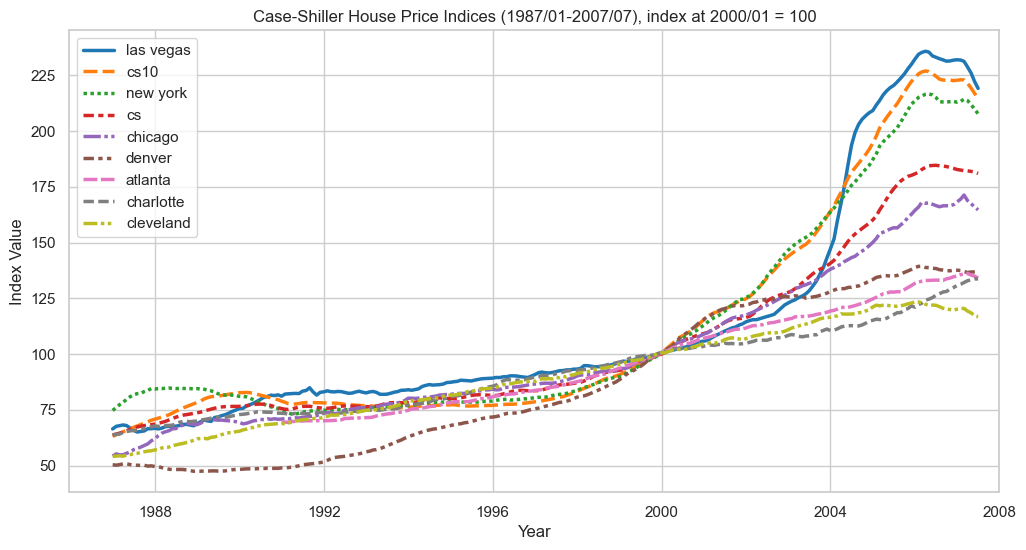

In [42]:
# Case-Shiller House Price Indices

# Select HPI columns and define labels
# Note: Column names must match those generated in 1_data_download.ipynb
hpi_cols = ['cs', 'cs10', 'cleveland', 'denver', 'chicago', 'las vegas', 'new york', 'atlanta', 'charlotte']

# use in thesis graphs only
labels_map = {
    'cs': 'National',
    'cs10': '10-City',
    'cleveland': 'Cleveland',
    'denver': 'Denver',   
    'las vegas': 'Las Vegas',
    'new york': 'New York'
}

# Check if columns exist before plotting
available_cols = [col for col in hpi_cols if col in df_var.columns]

if available_cols:
    # Sort columns by the last value (descending)
    last_values = df_var[available_cols].iloc[-1]
    sorted_cols = last_values.sort_values(ascending=False).index.tolist()

    # Create sorted dataframe with proper labels
    df_plot = df_var[sorted_cols]

    # Plot
    plot_series(df_plot, title='Case-Shiller House Price Indices (1987/01-2007/07), index at 2000/01 = 100', 
                ylabel='Index Value', xlim_right='2008-01-01', palette='tab10')
else:
    print("No HPI columns found in the dataset.")

## 6. Economic Indicators
Visualizing Federal Funds Rate, Unemployment Rate, and PCE from 1987.

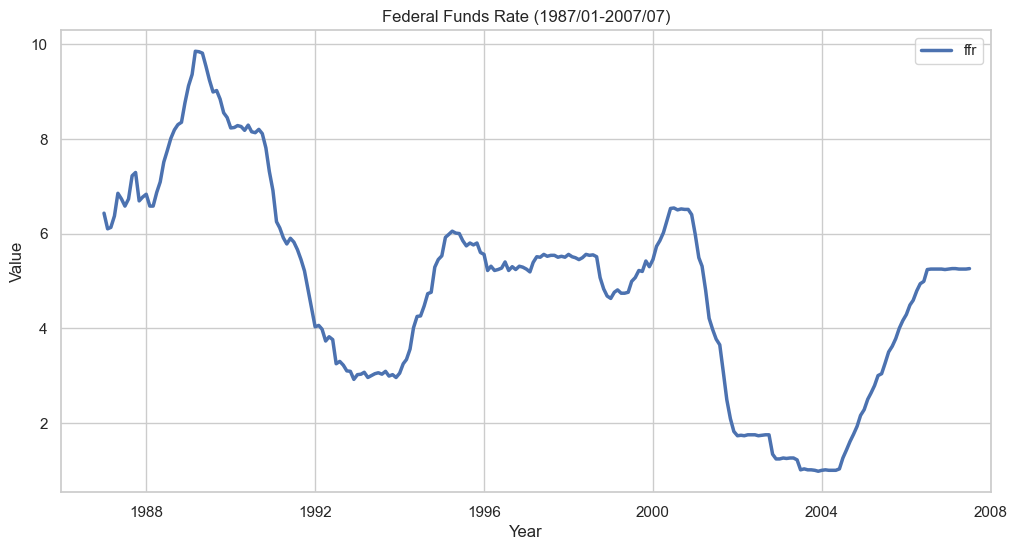

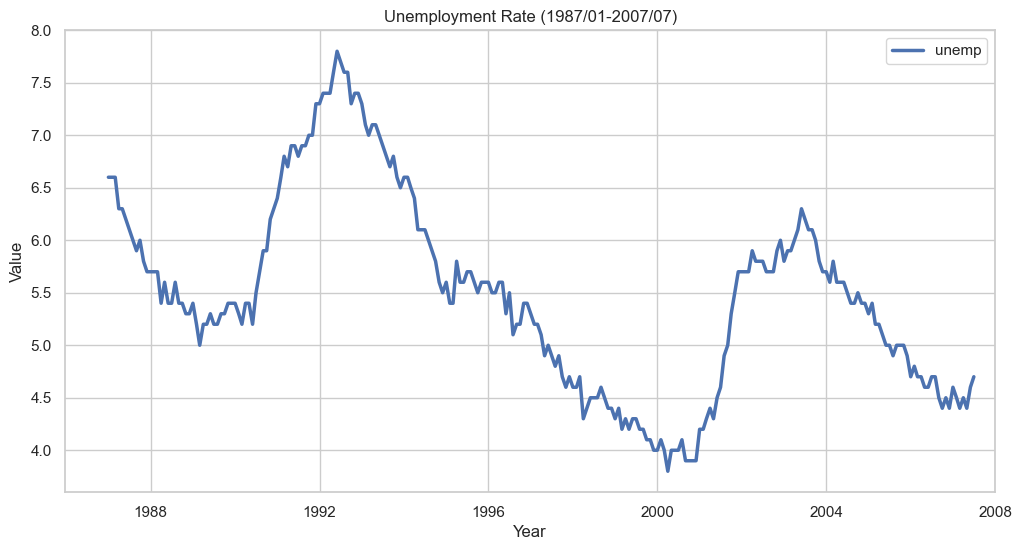

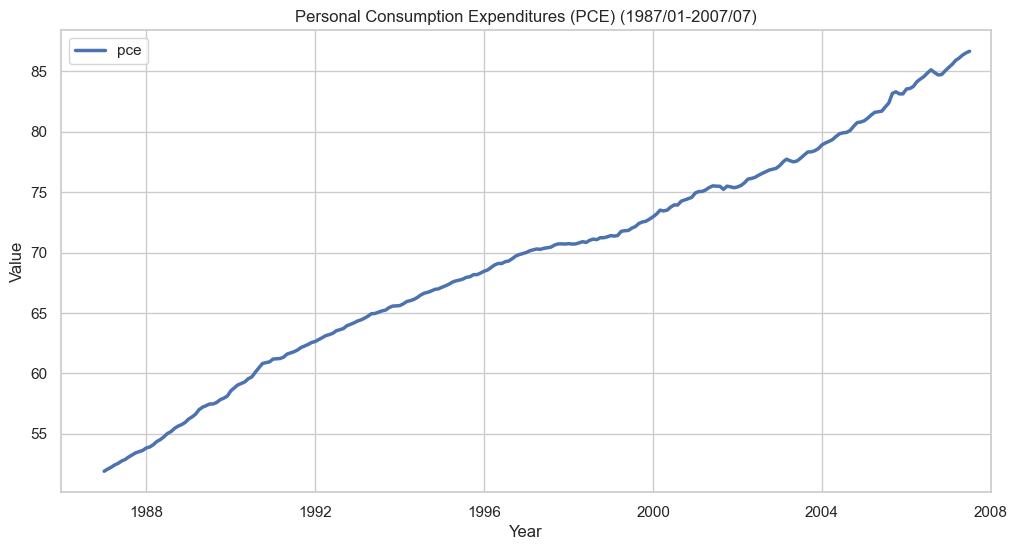

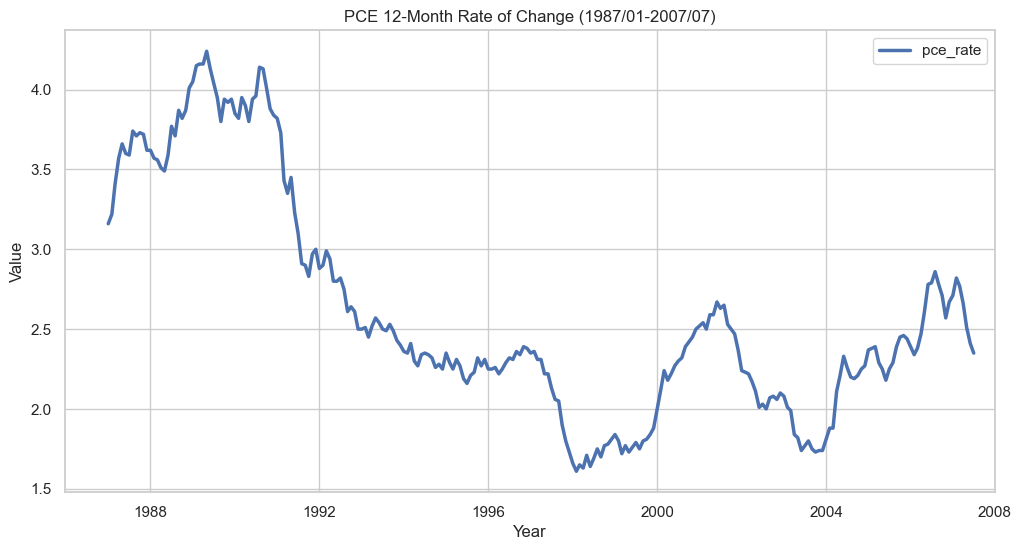

In [43]:
# Economic Indicators
econ_cols = {
    'ffr': 'Federal Funds Rate',
    'unemp': 'Unemployment Rate',
    'pce': 'Personal Consumption Expenditures (PCE)',
    'pce_rate': 'PCE 12-Month Rate of Change'
}

for col, title in econ_cols.items():
    if col in df_var.columns:
        plot_series(df_var[[col]], title=f'{title} (1987/01-2007/07)', ylabel='Value', xlim_right='2008-01-01')

## 7. Housing Starts and Recessions
Visualizing Housing Starts from 1959 with recession shading.

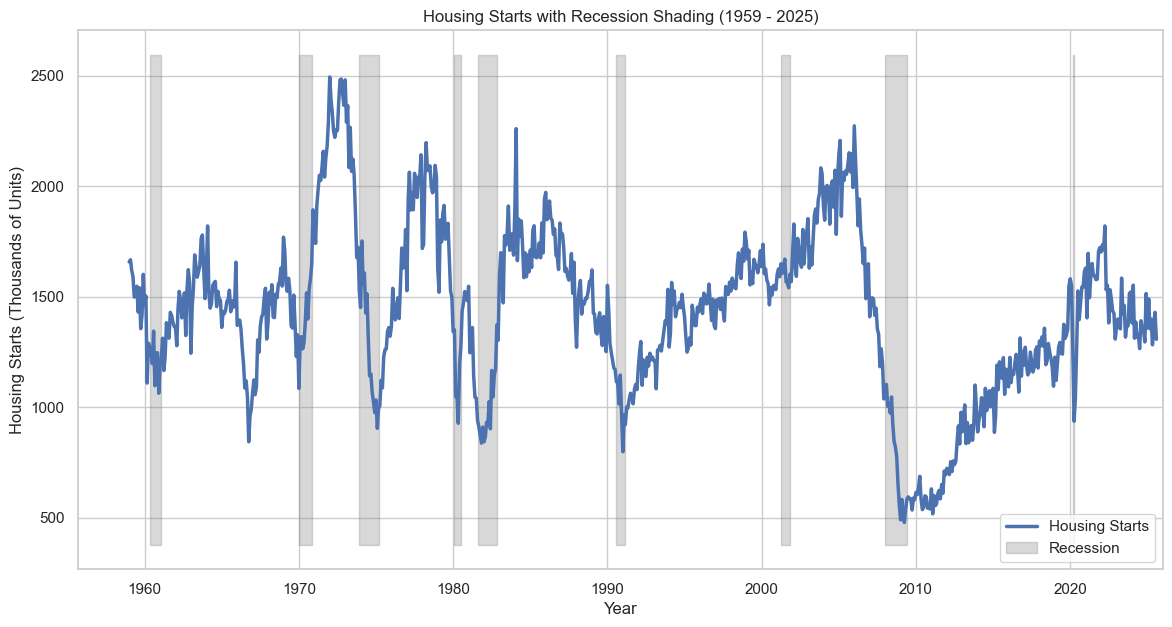

In [44]:
# Housing Starts and Recessions

plt.figure(figsize=(14, 7))
sns.lineplot(data=df_visuals, x=df_visuals.index, y='National_housing starts', linewidth=2.5, label='Housing Starts')

# Shade recessions
y_min, y_max = plt.ylim()
plt.fill_between(df_visuals.index, y_min, y_max, where=df_visuals['National_recessions'] == 1, 
                 color='grey', alpha=0.3, label='Recession')

plt.title('Housing Starts with Recession Shading (1959 - 2025)')
plt.ylabel('Housing Starts (Thousands of Units)')
plt.xlabel('Year')
plt.xlim(right=pd.Timestamp('2026-01-01'))
plt.legend()
plt.show()